In [3]:
import pandas as pd
import csv

def robust_load_csv(file_path):
    """
    Robustly load a CSV:
    - Reads any number of tag columns (even with commas inside)
    - Merges them into one 'tags' column
    - Guarantees consistent column count
    """
    with open(file_path, "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        rows = list(reader)

    header = rows[0]
    # Find indices for the columns we know are fixed
    start_idx = header.index("oldRating") + 1
    end_idx = header.index("solveTime")
    
    # Calculate the number of columns that should come AFTER the tags
    num_suffix_cols = len(header) - end_idx

    processed_rows = []
    for row in rows[1:]:
        # Define the parts of the row based on the fixed columns
        prefix_data = row[:start_idx]
        
        # Use negative indexing to correctly find the suffix columns
        # This works even if the total number of columns in `row` is unexpected
        suffix_data = row[-num_suffix_cols:] if num_suffix_cols > 0 else []
        
        # The tags are everything in between the prefix and suffix
        # Handle the edge case where there are no suffix columns
        if num_suffix_cols > 0:
            tags_raw = row[start_idx:-num_suffix_cols]
        else:
            tags_raw = row[start_idx:]
            
        tags = [t.strip() for t in tags_raw if t.strip()]

        # Rebuild the row with a consistent structure
        new_row = prefix_data + [tags] + suffix_data
        processed_rows.append(new_row)

    # Build the corresponding clean header
    new_header = header[:start_idx] + ["tags"] + header[end_idx:]

    return pd.DataFrame(processed_rows, columns=new_header)

def process_df(df):
    """
    Adds timeDiff per handle+contestId.
    """
    df = df.copy()
    df["solveTime"] = df["solveTime"].astype(int)
    df["timeDiff"] = pd.NA

    # Using transform is more idiomatic and often faster than iterating
    df = df.sort_values(by=["handle", "contestId", "solveTime"])
    df['timeDiff'] = df.groupby(["handle", "contestId"])['solveTime'].diff().fillna(df['solveTime'])
    df['timeDiff'] = df['timeDiff'].astype(int)
    
    return df

if __name__ == "__main__":
    df_input = robust_load_csv("data.csv")
    df_with_diffs = process_df(df_input)
    df_with_diffs.to_csv("processed_data.csv", index=False)
    print("✅ Processed CSV saved as 'processed_data.csv'")

✅ Processed CSV saved as 'processed_data.csv'


In [19]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast # To safely evaluate string-represented lists



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer

# Set plot style for better visuals
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load the processed data
df = pd.read_csv("processed_data.csv")

# --- Critical Step: Convert comma-separated string to a list of tags ---
# We fill NaNs with an empty string to prevent errors, then split by comma.
# A list comprehension cleans up any leading/trailing whitespace from each tag.
df['tags'] = df['tags'].fillna('').apply(lambda x: [tag.strip() for tag in x.split(',') if tag.strip()])

# Select columns and set correct data types
df = df[['oldRating', 'rating', 'tags', 'timeDiff']].copy()
df.dropna(inplace=True)
df['oldRating'] = df['oldRating'].astype(int)
df['rating'] = df['rating'].astype(int)

print("Shape after loading and initial cleaning:")
print(df.shape)
df.head()


Shape after loading and initial cleaning:
(157187, 4)


,oldRating,rating,tags,timeDiff
0,0,800,"[['constructive algorithms', 'greedy']]",688
1,1066,800,"[['constructive algorithms', 'greedy']]",915
2,1066,1100,"[['greedy', 'math']]",1823
3,1029,800,"[['greedy', 'sortings']]",1119
4,1029,1000,[['greedy']],3022


In [5]:
rating_gap = df['rating'] - df['oldRating']
# Remove submissions where the problem is rated 400+ points above the user
df = df[rating_gap <= 400]

# 2. Filter by timeDiff to remove noise
# Remove submissions faster than 15 seconds (likely not genuine attempts)
df = df[df['timeDiff'] > 15]
# Remove the top 1% of the slowest submissions
time_cap = df['timeDiff'].quantile(0.99)
df = df[df['timeDiff'] <= time_cap]

print("\nShape after removing outliers:")
print(df.shape)

df.head()


Shape after removing outliers:
(144020, 4)


,oldRating,rating,tags,timeDiff
1,1066,800,"[['constructive algorithms', 'greedy']]",915
2,1066,1100,"[['greedy', 'math']]",1823
3,1029,800,"[['greedy', 'sortings']]",1119
4,1029,1000,[['greedy']],3022
5,1152,800,"[['constructive algorithms', 'greedy']]",411


In [24]:
# 1. Filter for ratings in the requested range
mask = (df['rating'] >= 800) & (df['rating'] <= 3500)
rating_subset = df.loc[mask, 'rating']

# 2. Get counts and sort by rating (index)
# We use sort_index() so the output goes from 800 -> 3500
rating_distribution = rating_subset.value_counts().sort_index()

print("--- Problem Rating Counts (800 to 3500) ---")
print(rating_distribution)

# Optional: Total problems in this range
print(f"\nTotal problems in range: {rating_distribution.sum()}")

--- Problem Rating Counts (800 to 3500) ---
rating
800     46385
900     24506
1000    17157
1100    14180
1200     7355
1300    16197
1400     7097
1500     2576
1700     5017
1800      954
2000        2
2100     1372
2200       13
2300      504
2400      391
2600      217
2800       57
3200        9
3300       15
3400       12
3500        4
Name: count, dtype: int64

Total problems in range: 144020


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time
import ast
import re

def clean_tags_v3(val):
    """Bulletproof flattener for nested lists/arrays/strings."""
    # Handle actual list/array types first to avoid truthiness errors
    if isinstance(val, (list, np.ndarray, tuple)):
        # Deep flatten
        items = []
        def _flatten(l):
            for i in l:
                if isinstance(i, (list, np.ndarray, tuple)): _flatten(i)
                else: items.append(str(i).strip())
        _flatten(val)
        return list(set(items))
    
    # Handle None or NaN for non-array types
    if pd.isna([val])[0]: # Safer scalar check
        return []
    
    # Handle strings that look like lists
    if isinstance(val, str):
        try:
            val_eval = ast.literal_eval(val.replace('[[', '[').replace(']]', ']'))
            return clean_tags_v3(val_eval)
        except:
            return [val.strip()]
            
    return [str(val).strip()]

# 1. Process Tags
df['tags_cleaned'] = df['tags'].apply(clean_tags_v3)

# 2. Multi-Hot Encoding
mlb = MultiLabelBinarizer()
tag_matrix = mlb.fit_transform(df['tags_cleaned'])
# Prefix tag names to prevent collisions with 'rating' or 'oldRating'
tag_cols = [f"tag_{re.sub(r'\W+', '_', c)}" for c in mlb.classes_]
tag_df = pd.DataFrame(tag_matrix, columns=tag_cols, index=df.index)

# 3. Build Feature Matrix X (Using specific prefixes for all columns)
X = pd.concat([
    df[['oldRating']].rename(columns={'oldRating': 'user_rating'}),
    df[['rating']].rename(columns={'rating': 'problem_rating'}),
    tag_df
], axis=1)

# 4. Final Sanitization (Remove duplicates and special characters for LightGBM)
X = X.loc[:, ~X.columns.duplicated()].copy()
y = df['timeDiff']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Final Dataset: {X_train.shape[0]} rows, {X_train.shape[1]} unique features.")

df.shape

features = X.columns.tolist()

print(f"Total Features: {len(features)}")
print("--- Full Feature List ---")
for i, feature in enumerate(features, 1):
    print(f"{i}. {feature}")



Final Dataset: 115216 rows, 24 unique features.
Total Features: 24
--- Full Feature List ---
1. user_rating
2. problem_rating
3. tag__brute_force_
4. tag__constructive_algorithms_
5. tag__data_structures_
6. tag__dfs_and_similar_
7. tag__divide_and_conquer_
8. tag__dp_
9. tag__fft_
10. tag__geometry_
11. tag__graphs_
12. tag__greedy_
13. tag__implementation_
14. tag__math_
15. tag__number_theory_
16. tag__shortest_paths_
17. tag__sortings_
18. tag__ternary_search_
19. tag__trees_
20. tag__two_pointers_
21. tag__binary_search_
22. tag__bitmasks_
23. tag__combinatorics_
24. tag__games_
--- Full Tag Counts ---
greedy                      41111
bitmasks                    15627
binary search               11742
brute force                  9157
constructive algorithms      8799
math                         8470
implementation               6772
dp                           6723
games                        6097
trees                        3546
geometry                     2591
two pointer

Training on 115147 rows...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002684 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 313
[LightGBM] [Info] Number of data points in the train set: 115147, number of used features: 21
[LightGBM] [Info] Start training from score 6.952641

--- COMPREHENSIVE PERFORMANCE ---
   Model    MAE (s)  MedAE (s)    RMSE (s)  R2 (Log)     MSLE
 XGBoost 717.016189 431.527710 1078.217468  0.402370 0.465077
LightGBM 718.984196 433.227317 1080.661759  0.400715 0.466364


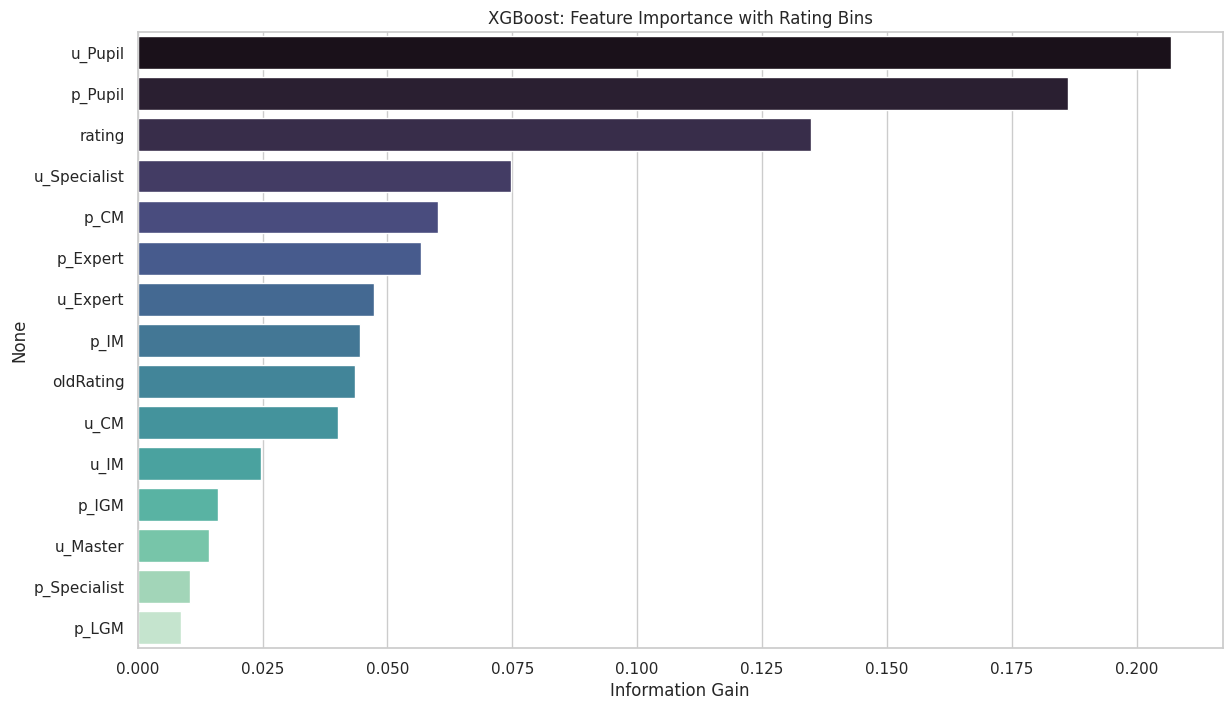

In [25]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, median_absolute_error, 
    mean_squared_error, r2_score, mean_squared_log_error
)

# ==========================================
# 1. DATA PREPARATION & CF BUCKETING
# ==========================================
# Official CF Rank Thresholds
bins = [0, 1199, 1399, 1599, 1899, 2099, 2299, 2399, 2599, 2999, 5000]
labels = ['Pupil', 'Specialist', 'Expert', 'CM', 'Master', 'IM', 'GM', 'IGM', 'LGM', 'Tourist']

df_model = df.dropna(subset=['timeDiff', 'rating', 'oldRating']).copy()
df_model = df_model[(df_model['timeDiff'] > 30) & (df_model['timeDiff'] < 10800)]
df_model['log_target'] = np.log1p(df_model['timeDiff'])

# Create Categorical Rank Buckets
df_model['user_rank'] = pd.cut(df_model['oldRating'], bins=bins, labels=labels)
df_model['problem_rank'] = pd.cut(df_model['rating'], bins=bins, labels=labels)

# ==========================================
# 2. FEATURE ENGINEERING (TAGS + BIN ONE-HOT)
# ==========================================
# Process 'Big Five' Tags
target_tags = ['greedy', 'brute force', 'math', 'implementation', 'dp']
for tag in target_tags:
    col_name = f'tag_{tag.replace(" ", "_")}'
    df_model[col_name] = df_model['tags'].apply(
        lambda x: 1 if isinstance(x, str) and tag in [t.strip() for t in x.split(',')] else 0
    )

# One-Hot Encoding for User and Problem Ranks
# This allows the model to treat 'Expert' vs 'Master' as distinct logical states
df_model = pd.get_dummies(df_model, columns=['user_rank', 'problem_rank'], prefix=['u', 'p'])

# Define Features: Raw Ratings + Binned Ranks + Tags
rank_cols = [c for c in df_model.columns if c.startswith('u_') or c.startswith('p_')]
tag_cols = [f'tag_{t.replace(" ", "_")}' for t in target_tags]
feature_cols = ['rating', 'oldRating'] + rank_cols + tag_cols

X = df_model[feature_cols]
y = df_model['log_target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# 3. TRAINING: XGBOOST & LIGHTGBM
# ==========================================
# XGBoost: Set colsample_bytree lower to force the model to use tags
xgb_model = xgb.XGBRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.6, tree_method='hist', random_state=42
)

# LightGBM: Generally better at handling one-hot encoded categorical data
lgb_model = lgb.LGBMRegressor(
    n_estimators=1000, learning_rate=0.05, num_leaves=31, 
    importance_type='gain', random_state=42
)

print(f"Training on {X_train.shape[0]} rows...")
xgb_model.fit(X_train, y_train)
lgb_model.fit(X_train, y_train)

# ==========================================
# 4. ANALYTICAL EVALUATION & METRICS
# ==========================================
def get_full_metrics(model, X_test, y_test, name):
    preds_log = model.predict(X_test)
    y_true_sec = np.expm1(y_test)
    y_pred_sec = np.expm1(preds_log)
    
    return {
        "Model": name,
        "MAE (s)": mean_absolute_error(y_true_sec, y_pred_sec),
        "MedAE (s)": median_absolute_error(y_true_sec, y_pred_sec),
        "RMSE (s)": np.sqrt(mean_squared_error(y_true_sec, y_pred_sec)),
        "R2 (Log)": r2_score(y_test, preds_log),
        "MSLE": mean_squared_log_error(y_true_sec, np.clip(y_pred_sec, 1e-6, None))
    }

results = pd.DataFrame([
    get_full_metrics(xgb_model, X_test, y_test, "XGBoost"),
    get_full_metrics(lgb_model, X_test, y_test, "LightGBM")
])

print("\n--- COMPREHENSIVE PERFORMANCE ---")
print(results.to_string(index=False))

# ==========================================
# 5. FEATURE IMPORTANCE VISUALIZATION
# ==========================================
plt.figure(figsize=(14, 8))
feat_imp = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
sns.barplot(x=feat_imp.values[:15], y=feat_imp.index[:15], palette='mako')
plt.title("XGBoost: Feature Importance with Rating Bins")
plt.xlabel("Information Gain")
plt.show()

In [7]:
# Calculate the sum of each tag column in the feature matrix X
# This works because tags are one-hot encoded (1 if present, 0 if not)
tag_counts = X.filter(like='tag_').sum().sort_values(ascending=False)

# Clean up the index names for display (removing the 'tag_' prefix)
tag_counts.index = [c.replace('tag_', '').replace('_', ' ') for c in tag_counts.index]

print("--- Full Tag Counts ---")
print(tag_counts)

--- Full Tag Counts ---
greedy                      41111
bitmasks                    15627
binary search               11742
brute force                  9157
constructive algorithms      8799
math                         8470
implementation               6772
dp                           6723
games                        6097
trees                        3546
geometry                     2591
two pointers                 2439
sortings                     2426
combinatorics                 936
divide and conquer            399
data structures               391
graphs                        391
shortest paths                391
dfs and similar               313
fft                            15
ternary search                 13
number theory                   2
dtype: int64


Training on 115216 rows with 9 features...

--- PERFORMANCE METRICS ---
MAE (Avg Error): 739.8243
Median AE (Typical Error): 516.2647
RMSE (Outlier Sensitive): 1034.9221
R2 Score: 0.3388
MSLE (Relative Accuracy): 0.5144
Training Time: 3.45 seconds


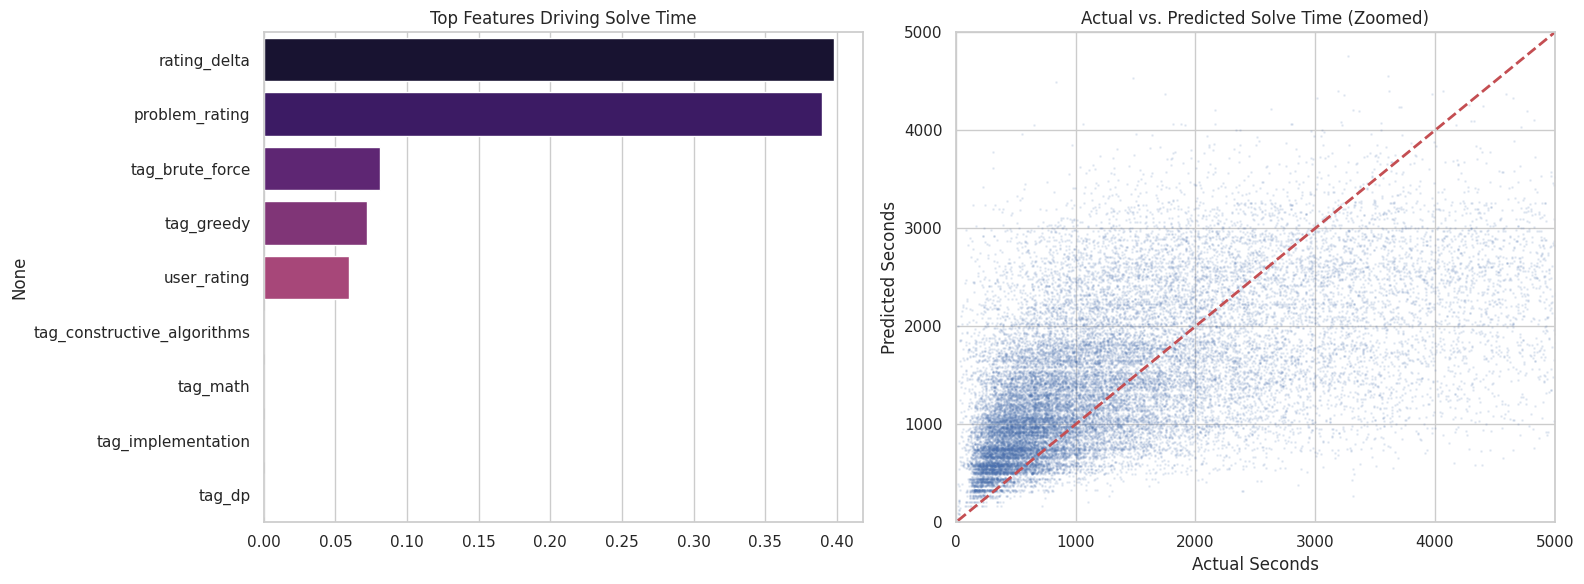

In [16]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, 
    median_absolute_error, 
    mean_squared_error, 
    r2_score, 
    mean_squared_log_error
)
import time

# ==========================================
# 1. DATA PREPARATION & FEATURE FILTERING
# ==========================================
# We filter the 157k+ rows down to the core drivers of solve time
def prepare_final_xgb_data(df, X_df):
    # Select specific high-frequency tags requested
    requested_tags = [
        'greedy','brute_force', 
        'constructive_algorithms', 'math', 'implementation', 'dp'
    ]
    
    # Map to internal column names and verify existence
    tag_cols = [f"tag_{t.replace(' ', '_')}" for t in requested_tags]
    existing_tag_cols = [c for c in tag_cols if c in X_df.columns]
    
    # Numerical features: Current user strength vs. Problem difficulty
    X_subset = pd.DataFrame({
        'user_rating': df['oldRating'],
        'problem_rating': df['rating'],
        'rating_delta': df['rating'] - df['oldRating'] # Captures "stretch" problems
    })
    
    # Combine ratings with the selected 8 tags
    X_final = pd.concat([X_subset, X_df[existing_tag_cols]], axis=1)
    y = df['timeDiff']
    
    return X_final, y

# Process the data
X_final, y_final = prepare_final_xgb_data(df, X)

# 80/20 Train-Test Split (Explains the shift from 150k to ~111k training rows)
X_train, X_test, y_train, y_test = train_test_split(X_final, y_final, test_size=0.2, random_state=42)

# ==========================================
# 2. TUNED XGBOOST TRAINING
# ==========================================
# Using Histogram-based splits for speed on 100k+ samples
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.9,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

print(f"Training on {X_train.shape[0]} rows with {X_train.shape[1]} features...")
start_time = time.time()
xgb_model.fit(X_train, y_train)
train_duration = time.time() - start_time

# Predictions
preds = xgb_model.predict(X_test)
# Ensure no negative predictions (solve time can't be negative)
preds = np.clip(preds, 1, None)

# ==========================================
# 3. MULTI-METRIC VALIDATION
# ==========================================
metrics = {
    "MAE (Avg Error)": mean_absolute_error(y_test, preds),
    "Median AE (Typical Error)": median_absolute_error(y_test, preds),
    "RMSE (Outlier Sensitive)": np.sqrt(mean_squared_error(y_test, preds)),
    "R2 Score": r2_score(y_test, preds),
    "MSLE (Relative Accuracy)": mean_squared_log_error(y_test, preds)
}

print("\n--- PERFORMANCE METRICS ---")
for name, val in metrics.items():
    print(f"{name}: {val:.4f}")
print(f"Training Time: {train_duration:.2f} seconds")

# ==========================================
# 4. VISUALIZATION & DIAGNOSTICS
# ==========================================
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Feature Importance
# Shows which of the 8 tags actually matter most compared to rating

feat_imp = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
sns.barplot(x=feat_imp.values, y=feat_imp.index, ax=ax[0], palette='magma')
ax[0].set_title('Top Features Driving Solve Time')

# Plot 2: Prediction Errors (Actual vs Predicted)
# Visualizes the "long tail" of solve times

ax[1].scatter(y_test, preds, alpha=0.1, s=1)
ax[1].plot([y_test.min(), 5000], [y_test.min(), 5000], 'r--', lw=2) # Zoomed to first 5000s
ax[1].set_xlim(0, 5000)
ax[1].set_ylim(0, 5000)
ax[1].set_title('Actual vs. Predicted Solve Time (Zoomed)')
ax[1].set_xlabel('Actual Seconds')
ax[1].set_ylabel('Predicted Seconds')

plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error, median_absolute_error, 
    mean_squared_error, r2_score, mean_squared_log_error
)
import time
import json

# ==========================================
# 1. DATA PREPARATION & REFINED CLEANING
# ==========================================
# Filtering outliers is critical for CP data to remove 'AFK' sessions
df_model = df.dropna(subset=['timeDiff']).copy()
df_model = df_model[(df_model['timeDiff'] > 30) & (df_model['timeDiff'] < 10800)] # Cap at 3 hours

# Target Transformation: Log-scale reduces the impact of the 'long tail'
df_model['log_target'] = np.log1p(df_model['timeDiff'])

# ==========================================
# 2. FEATURE ENGINEERING (Old Logic + Analysis)
# ==========================================
# Using your specific logic for the Big Eight tags
target_tags = [
    'greedy', 'brute force', 'math', 'implementation', 'dp'
]

for tag in target_tags:
    col_name = f'tag_{tag.replace(" ", "_")}'
    # Applying your logic: check if tag exists in the comma-separated string
    df_model[col_name] = df_model['tags'].apply(
        lambda x: 1 if isinstance(x, str) and tag in [t.strip() for t in x.split(',')] else 0
    )

# Adding analytical features to improve predictive power
df_model['rating_delta'] = df_model['rating'] - df_model['oldRating']
df_model['difficulty_ratio'] = df_model['rating'] / (df_model['oldRating'] + 1e-9)

feature_cols = ['rating', 'oldRating', 'rating_delta', 'difficulty_ratio'] + \
               [f'tag_{t.replace(" ", "_")}' for t in target_tags]

X = df_model[feature_cols]
y = df_model['log_target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# 3. HYPERPARAMETER TUNING (RandomizedSearch)
# ==========================================
# More efficient than GridSearch for high-dimensional XGBoost models
param_dist = {
    'n_estimators': [500, 1000],
    'max_depth': [5, 7, 9],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 0.9],
    'colsample_bytree': [0.7, 0.8],
    'reg_lambda': [1, 2, 5],
    'gamma': [0.1, 0.2]
}

xgb_base = xgb.XGBRegressor(tree_method='hist', random_state=42, n_jobs=-1)

random_search = RandomizedSearchCV(
    xgb_base, param_distributions=param_dist, 
    n_iter=15, cv=3, scoring='neg_mean_absolute_error', verbose=1
)

print("Starting analytical tuning...")
random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_

# ==========================================
# 4. COMPREHENSIVE EVALUATION
# ==========================================
y_pred_log = best_model.predict(X_test)

# Inverse transform to actual seconds
y_test_orig = np.expm1(y_test)
y_pred_orig = np.expm1(y_pred_log)

metrics = {
    "Log MAE": mean_absolute_error(y_test, y_pred_log),
    "Seconds MAE": mean_absolute_error(y_test_orig, y_pred_orig),
    "Seconds Median AE": median_absolute_error(y_test_orig, y_pred_orig),
    "R2 (Log Scale)": r2_score(y_test, y_pred_log)
}

print("\n--- ANALYTICAL RESULTS ---")
for k, v in metrics.items():
    print(f"{k:20}: {v:.4f}")

Starting analytical tuning...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

--- ANALYTICAL RESULTS ---
Log MAE             : 0.5337
Seconds MAE         : 715.5312
Seconds Median AE   : 430.2307
R2 (Log Scale)      : 0.4051


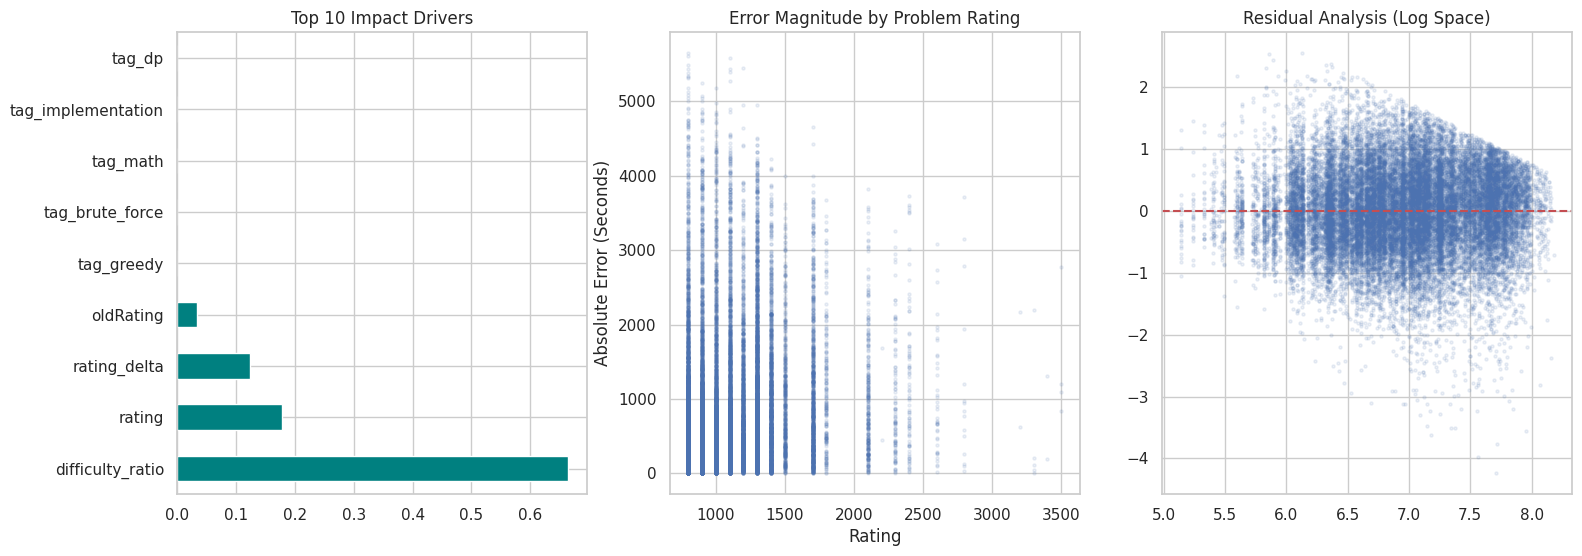

Metric               Value          
-----------------------------------
Log MAE              0.5337         
Seconds MAE          715.53         
Seconds Median AE    430.23         
Seconds RMSE         1076.47        
R² (Log Scale)       0.4051         
MSLE                 0.4629         


In [21]:
plt.figure(figsize=(18, 6))

# A. Feature Importance: Do specific tags actually affect your time?
plt.subplot(1, 3, 1)
feat_imp = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
feat_imp.head(10).plot(kind='barh', color='teal')
plt.title("Top 10 Impact Drivers")

# B. Error Magnitude vs Problem Rating
# This shows if the model is more "confused" by harder problems
plt.subplot(1, 3, 2)
errors = np.abs(y_test_orig - y_pred_orig)
plt.scatter(X_test['rating'], errors, alpha=0.1, s=5)
plt.title("Error Magnitude by Problem Rating")
plt.xlabel("Rating")
plt.ylabel("Absolute Error (Seconds)")

# C. Residual Plot: Checking for Bias
plt.subplot(1, 3, 3)
residuals = y_test - y_pred_log
plt.scatter(y_pred_log, residuals, alpha=0.1, s=5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Residual Analysis (Log Space)")
plt.show()


from sklearn.metrics import mean_squared_error, mean_squared_log_error

# Root Mean Squared Error (RMSE) in original seconds
# This tells you the standard deviation of your prediction errors
rmse_seconds = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))

# Mean Squared Logarithmic Error (MSLE)
# Measures relative error; useful for targets spanning multiple orders of magnitude
msle = mean_squared_log_error(y_test_orig, np.clip(y_pred_orig, 1e-6, None))

print(f"{'Metric':<20} {'Value':<15}")
print(f"{'-'*35}")
print(f"{'Log MAE':<20} {metrics['Log MAE']:<15.4f}")
print(f"{'Seconds MAE':<20} {metrics['Seconds MAE']:<15.2f}")
print(f"{'Seconds Median AE':<20} {metrics['Seconds Median AE']:<15.2f}")
print(f"{'Seconds RMSE':<20} {rmse_seconds:<15.2f}")
print(f"{'R² (Log Scale)':<20} {metrics['R2 (Log Scale)']:<15.4f}")
print(f"{'MSLE':<20} {msle:<15.4f}")

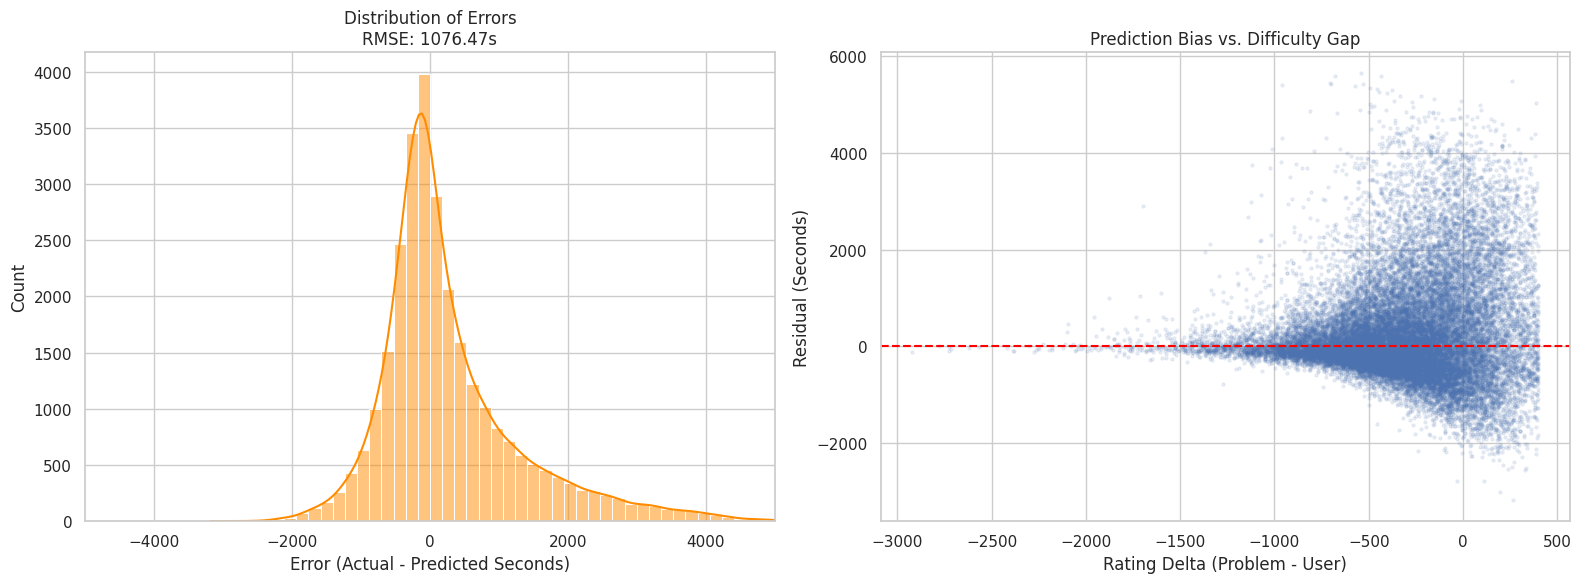

In [22]:
plt.figure(figsize=(16, 6))

# A. Error Distribution (Seconds)
# A wide bell curve indicates a high RMSE; a narrow one indicates a more stable model
plt.subplot(1, 2, 1)
sns.histplot(y_test_orig - y_pred_orig, bins=50, kde=True, color='darkorange')
plt.title(f'Distribution of Errors\nRMSE: {rmse_seconds:.2f}s')
plt.xlabel('Error (Actual - Predicted Seconds)')
plt.xlim(-5000, 5000) # Focusing on the bulk of solves

# B. Accuracy by Difficulty Gap (Rating Delta)
# Visualizes if the model struggles more with "Challenge" problems
plt.subplot(1, 2, 2)
plt.scatter(X_test['rating_delta'], (y_test_orig - y_pred_orig), alpha=0.1, s=5)
plt.axhline(0, color='red', linestyle='--')
plt.title('Prediction Bias vs. Difficulty Gap')
plt.xlabel('Rating Delta (Problem - User)')
plt.ylabel('Residual (Seconds)')

plt.tight_layout()
plt.show()

Starting Training on 115147 samples...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

ANALYTICAL METRIC         | VALUE          
Log-Scale MAE             | 0.5338         
Log-Scale R² Score        | 0.4048         
MSLE                      | 0.4632         
---------------------------------------------
Seconds MAE (Avg Error)   | 715.52         s
Seconds Median AE         | 430.39         s
Seconds RMSE              | 1076.50        s
Training Duration         | 52.28          s


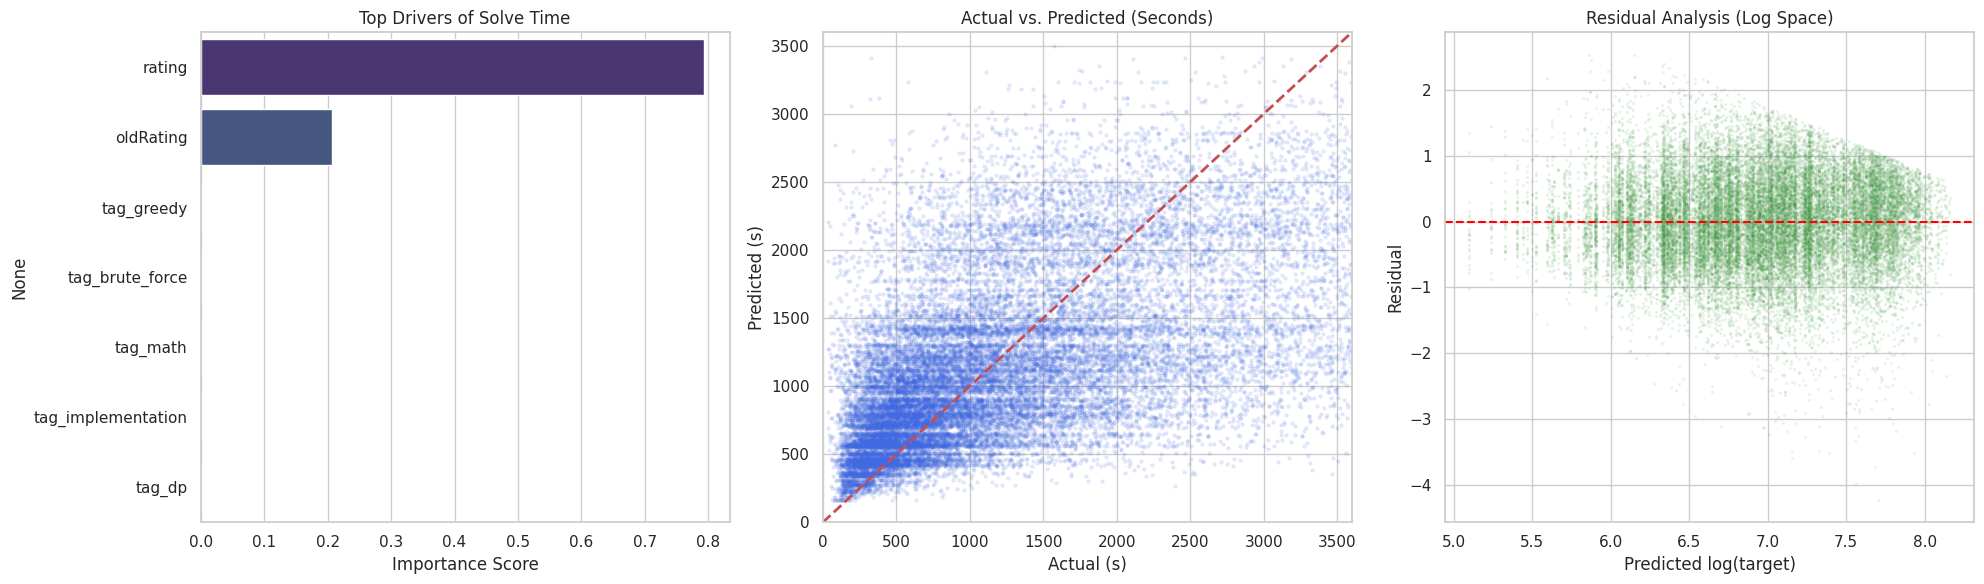

TypeError: `_estimator_type` undefined.  Please use appropriate mixin to define estimator type.

In [23]:
#new try now 
import pandas as pd

import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error, median_absolute_error, 
    mean_squared_error, r2_score, mean_squared_log_error
)
import time
import json

# ==========================================
# 1. DATA PREPARATION & LOG-TRANSFORMATION
# ==========================================
# Phase 1: Cleaning and outlier removal to eliminate 'noise' from AFK sessions
df_model = df.dropna(subset=['timeDiff', 'rating', 'oldRating']).copy()
df_model = df_model[(df_model['timeDiff'] > 30) & (df_model['timeDiff'] < 10800)] # 30s to 3h range

# Target Transformation: Predicting Log(1+x) stabilizes variance for skewed solve times
df_model['log_target'] = np.log1p(df_model['timeDiff'])

# ==========================================
# 2. FEATURE ENGINEERING (RAW LOGIC)
# ==========================================
# Phase 2: Mapping your specific 'Big Five' tags into binary features
target_tags = ['greedy', 'brute force', 'math', 'implementation', 'dp']

for tag in target_tags:
    col_name = f'tag_{tag.replace(" ", "_")}'
    # Logic: Checking for specific tag existence within the comma-separated string
    df_model[col_name] = df_model['tags'].apply(
        lambda x: 1 if isinstance(x, str) and tag in [t.strip() for t in x.split(',')] else 0
    )

# Feature Selection: Strictly using Raw Ratings and Tag Features
# (Excludes pre-calculated delta and ratio features per your request)
feature_cols = ['rating', 'oldRating'] + [f'tag_{t.replace(" ", "_")}' for t in target_tags]

X = df_model[feature_cols]
y = df_model['log_target']

# 80/20 Split for training and final 'exam' validation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# 3. HYPERPARAMETER TUNING & TRAINING
# ==========================================
# Phase 3: Randomized Search to find the best tree structure for XGBoost
param_dist = {
    'n_estimators': [500, 1000],
    'max_depth': [6, 8, 10], 
    'learning_rate': [0.03, 0.05],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'reg_lambda': [1, 5, 10],
    'gamma': [0, 0.1, 0.2]
}

xgb_base = xgb.XGBRegressor(tree_method='hist', random_state=42, n_jobs=-1, objective='reg:squarederror')

print(f"Starting Training on {len(X_train)} samples...")
random_search = RandomizedSearchCV(
    xgb_base, param_distributions=param_dist, 
    n_iter=12, cv=3, scoring='neg_mean_absolute_error', verbose=1, random_state=42
)

start_time = time.time()
random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_
train_time = time.time() - start_time

# ==========================================
# 4. COMPREHENSIVE MULTI-METRIC EVALUATION
# ==========================================
# Phase 4: Inference and inverse transformation back to seconds
y_pred_log = best_model.predict(X_test)
y_test_orig = np.expm1(y_test)
y_pred_orig = np.expm1(y_pred_log)
# Clip results to ensure no negative time predictions
y_pred_orig = np.clip(y_pred_orig, 1, None)

# Calculating exhaustive metrics suite
mae_log = mean_absolute_error(y_test, y_pred_log)
mae_sec = mean_absolute_error(y_test_orig, y_pred_orig)
med_ae_sec = median_absolute_error(y_test_orig, y_pred_orig)
rmse_sec = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))
r2_log = r2_score(y_test, y_pred_log)
msle = mean_squared_log_error(y_test_orig, y_pred_orig)

print("\n" + "="*45)
print(f"{'ANALYTICAL METRIC':<25} | {'VALUE':<15}")
print("="*45)
print(f"{'Log-Scale MAE':<25} | {mae_log:<15.4f}")
print(f"{'Log-Scale R² Score':<25} | {r2_log:<15.4f}")
print(f"{'MSLE':<25} | {msle:<15.4f}")
print(f"{'-'*45}")
print(f"{'Seconds MAE (Avg Error)':<25} | {mae_sec:<15.2f}s")
print(f"{'Seconds Median AE':<25} | {med_ae_sec:<15.2f}s")
print(f"{'Seconds RMSE':<25} | {rmse_sec:<15.2f}s")
print(f"{'Training Duration':<25} | {train_time:<15.2f}s")
print("="*45)

# ==========================================
# 5. VISUALIZATION SUITE
# ==========================================
# Phase 5: Diagnostic plots for Bias, Variance, and Feature Importance
fig, ax = plt.subplots(1, 3, figsize=(20, 6))

# A. Feature Importance: Raw Ratings vs. Big Five Tags

feat_imp = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
sns.barplot(x=feat_imp.values, y=feat_imp.index, ax=ax[0], palette='viridis')
ax[0].set_title('Top Drivers of Solve Time')
ax[0].set_xlabel('Importance Score')

# B. Actual vs Predicted (Zoomed to first hour for clarity)

ax[1].scatter(y_test_orig, y_pred_orig, alpha=0.1, s=5, color='royalblue')
ax[1].plot([0, 3600], [0, 3600], 'r--', lw=2)
ax[1].set_xlim(0, 3600)
ax[1].set_ylim(0, 3600)
ax[1].set_title('Actual vs. Predicted (Seconds)')
ax[1].set_xlabel('Actual (s)')
ax[1].set_ylabel('Predicted (s)')

# C. Residual Analysis: Checking for Systematic Bias

residuals = y_test - y_pred_log
sns.scatterplot(x=y_pred_log, y=residuals, alpha=0.1, s=5, color='forestgreen', ax=ax[2])
ax[2].axhline(0, color='red', linestyle='--')
ax[2].set_title('Residual Analysis (Log Space)')
ax[2].set_xlabel('Predicted log(target)')
ax[2].set_ylabel('Residual')

plt.tight_layout()
plt.show()

# ==========================================
# 6. MODEL EXPORT
# ==========================================
best_model.save_model('cf_timetale_raw_xgboost.json')
print("\n✅ Analytical model and diagnostics complete!")

In [2]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time

# Prepare a validation set for early stopping
X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42)

results_pro = []

# --- Optimized LightGBM ---
# Using DART (Dropouts meet Multiple Additive Regression Trees) can sometimes handle high-variance CP data better
lgb_pro = lgb.LGBMRegressor(
    n_estimators=3000,
    learning_rate=0.02,        # Slow and steady for better precision
    num_leaves=127,            # Higher complexity for your 115k rows
    max_depth=10,              # Explicit depth limit to prevent overfitting
    min_child_samples=50,      # Ensure leaves have enough data points
    reg_alpha=0.1,             # L1 regularization
    reg_lambda=0.1,            # L2 regularization
    colsample_bytree=0.7,      # Feature subsampling
    random_state=42
)

print("Training Optimized LightGBM...")
start = time.time()
lgb_pro.fit(X_train_sub, y_train_sub, eval_set=[(X_val, y_val)], 
            callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)])
lgb_time = time.time() - start
lgb_preds = lgb_pro.predict(X_test)

results_pro.append({
    "Model": "LightGBM (Pro-Tuned)",
    "MAE": mean_absolute_error(y_test, lgb_preds),
    "RMSE": np.sqrt(mean_squared_error(y_test, lgb_preds)),
    "Train Time": round(lgb_time, 2)
})

# --- Optimized XGBoost ---
# Using Dart booster in XGBoost to match the complexity
xgb_pro = xgb.XGBRegressor(
    n_estimators=3000,
    learning_rate=0.02,
    max_depth=8,
    subsample=0.7,
    colsample_bytree=0.7,
    tree_method='hist',
    gamma=0.5,                 # Minimum loss reduction to split
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42
)

print("Training Optimized XGBoost...")
start = time.time()
xgb_pro.fit(X_train_sub, y_train_sub, eval_set=[(X_val, y_val)], verbose=False)
xgb_time = time.time() - start
xgb_preds = xgb_pro.predict(X_test)

results_pro.append({
    "Model": "XGBoost (Pro-Tuned)",
    "MAE": mean_absolute_error(y_test, xgb_preds),
    "RMSE": np.sqrt(mean_squared_error(y_test, xgb_preds)),
    "Train Time": round(xgb_time, 2)
})

print("\n--- PROFESSIONAL BENCHMARK RESULTS ---")
print(pd.DataFrame(results_pro))

NameError: name 'X_train' is not defined

/tmp/ipykernel_49844/408758345.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp.head(15), palette='viridis')


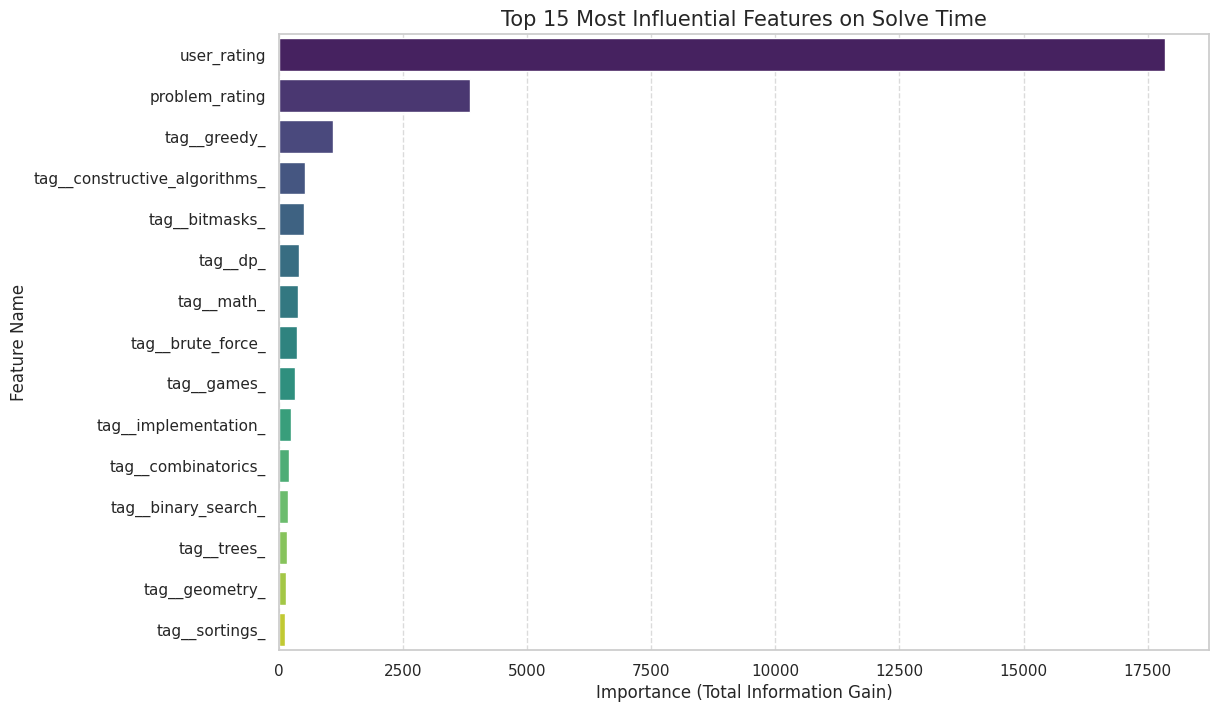

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract importance from the tuned LightGBM model
feat_imp = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': lgb_pro.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feat_imp.head(15), palette='viridis')
plt.title('Top 15 Most Influential Features on Solve Time', fontsize=15)
plt.xlabel('Importance (Total Information Gain)')
plt.ylabel('Feature Name')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

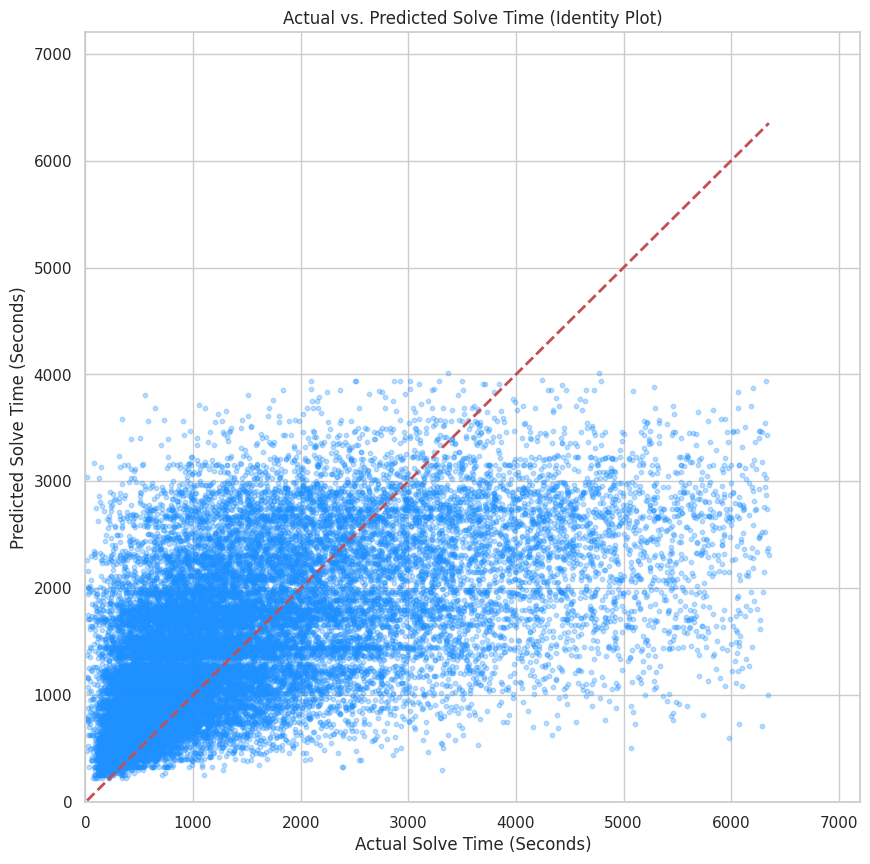

In [51]:
plt.figure(figsize=(10, 10))
plt.scatter(y_test, lgb_preds, alpha=0.3, color='dodgerblue', s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.xlabel('Actual Solve Time (Seconds)')
plt.ylabel('Predicted Solve Time (Seconds)')
plt.title('Actual vs. Predicted Solve Time (Identity Plot)')
# Capping limits for visibility (e.g., up to 2 hours)
plt.xlim(0, 7200) 
plt.ylim(0, 7200)
plt.show()

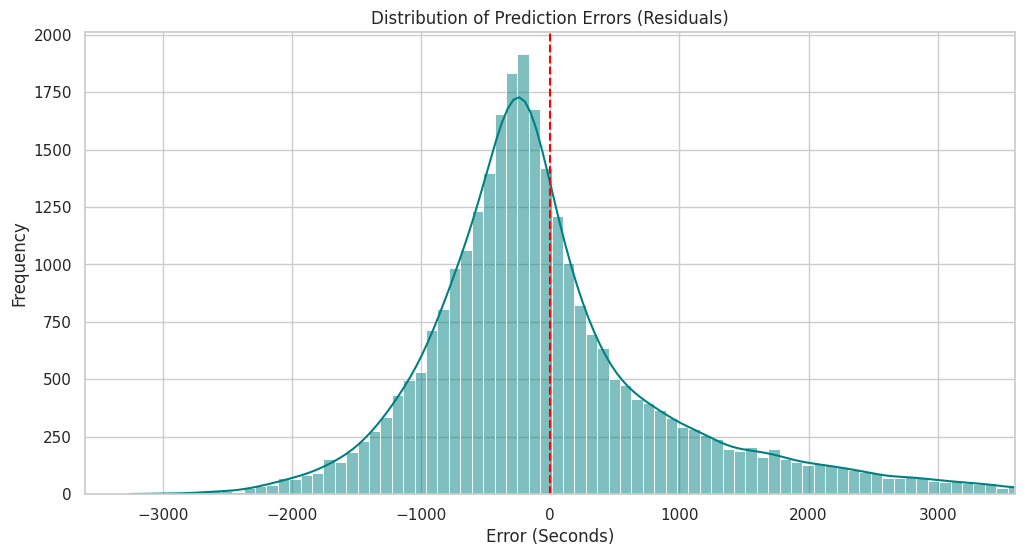

In [52]:
residuals = y_test - lgb_preds

plt.figure(figsize=(12, 6))
sns.histplot(residuals, kde=True, bins=100, color='teal')
plt.axvline(x=0, color='red', linestyle='--')
plt.title('Distribution of Prediction Errors (Residuals)')
plt.xlabel('Error (Seconds)')
plt.ylabel('Frequency')
# Focus on the bulk of the data
plt.xlim(-3600, 3600) 
plt.show()

In [56]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Scaling
scaler_x = StandardScaler()
X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

# 2. PyTorch DataLoaders
train_ds = TensorDataset(torch.FloatTensor(X_train_scaled), torch.FloatTensor(y_train_scaled))
test_ds = TensorDataset(torch.FloatTensor(X_test_scaled), torch.FloatTensor(y_test_scaled))
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=128)

In [57]:
class CPTimeNN(nn.Module):
    def __init__(self, input_dim):
        super(CPTimeNN, self).__init__()
        self.layer1 = nn.Linear(input_dim, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.layer2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)
        self.out = nn.Linear(64, 1)
        self.dropout = nn.Dropout(0.2)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.bn1(self.layer1(x)))
        x = self.dropout(x)
        x = self.relu(self.bn2(self.layer2(x)))
        x = self.out(x)
        return x

model = CPTimeNN(X_train.shape[1])
# HuberLoss is robust to outliers common in CP solve times
criterion = nn.HuberLoss() 
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

# Training with Loss Tracking
train_losses, val_losses = [], []
epochs = 50

for epoch in range(epochs):
    model.train()
    batch_losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    
    train_losses.append(np.mean(batch_losses))
    
    # Simple Validation check
    model.eval()
    with torch.no_grad():
        val_preds = model(torch.FloatTensor(X_test_scaled))
        v_loss = criterion(val_preds, torch.FloatTensor(y_test_scaled))
        val_losses.append(v_loss.item())

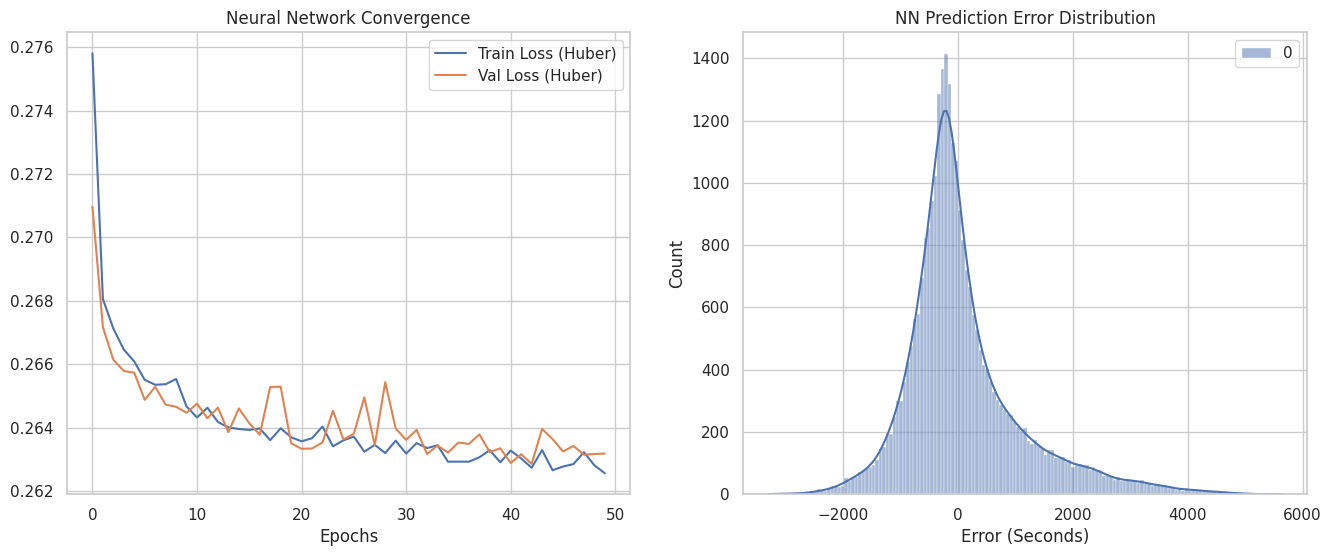

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Learning Curves
ax[0].plot(train_losses, label='Train Loss (Huber)')
ax[0].plot(val_losses, label='Val Loss (Huber)')
ax[0].set_title('Neural Network Convergence')
ax[0].set_xlabel('Epochs')
ax[0].legend()

# Plot 2: Error Distribution (Residuals)
model.eval()
with torch.no_grad():
    y_nn_scaled = model(torch.FloatTensor(X_test_scaled)).numpy()
    y_nn_final = scaler_y.inverse_transform(y_nn_scaled)
    nn_residuals = y_test.values.reshape(-1, 1) - y_nn_final

sns.histplot(nn_residuals, kde=True, ax=ax[1], color='purple')
ax[1].set_title('NN Prediction Error Distribution')
ax[1].set_xlabel('Error (Seconds)')
plt.show()

In [59]:
# metrics tracking
model.eval()
with torch.no_grad():
    y_nn_scaled = model(torch.FloatTensor(X_test_scaled))
    # Inverse scaling to get back to actual seconds
    y_nn_final = scaler_y.inverse_transform(y_nn_scaled.numpy())
    y_actual = y_test.values.reshape(-1, 1)

    mae = mean_absolute_error(y_actual, y_nn_final)
    rmse = np.sqrt(mean_squared_error(y_actual, y_nn_final))
    r2 = r2_score(y_actual, y_nn_final)

print(f"NN MAE: {mae:.2f} seconds")
print(f"NN RMSE: {rmse:.2f} seconds")
print(f"NN R2 Score: {r2:.4f}")


NN MAE: 710.14 seconds
NN RMSE: 1027.13 seconds
NN R2 Score: 0.3487


In [61]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import numpy as np

def final_nn_prep(df, X_df):
    # 1. Target Transformation: Predict log space to minimize outlier impact
    y_log = np.log1p(df['timeDiff'])
    
    # 2. Specific Tag Filtering
    keep_tags = ['tag_greedy', 'tag_constructive_algorithms', 'tag_dp']
    tag_cols = [c for c in keep_tags if c in X_df.columns]
    
    # 3. Feature Assembly
    X_subset = pd.DataFrame({
        'user_rating': df['oldRating'],
        'problem_rating': df['rating'],
        'rating_delta': df['rating'] - df['oldRating']
    })
    X_final = pd.concat([X_subset, X_df[tag_cols]], axis=1)
    
    return X_final, y_log

# Execute Prep
X_refined, y_log = final_nn_prep(df, X)

# Split and Scale
X_train, X_test, y_train, y_test = train_test_split(X_refined, y_log, test_size=0.2, random_state=42)

scaler_x = StandardScaler()
X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)

# Scale y_log for Neural Network stability
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

In [62]:
class CPTimeTaleNet(nn.Module):
    def __init__(self, input_dim):
        super(CPTimeTaleNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.2),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.net(x)

# Initialization
model = CPTimeTaleNet(X_train_scaled.shape[1])
criterion = nn.L1Loss() # MAE Loss: Directly optimizes for your goal
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

In [63]:
# Convert to Tensors
X_train_t = torch.FloatTensor(X_train_scaled)
y_train_t = torch.FloatTensor(y_train_scaled)
X_test_t = torch.FloatTensor(X_test_scaled)

train_losses = []
for epoch in range(100):
    model.train()
    optimizer.zero_grad()
    preds = model(X_train_t)
    loss = criterion(preds, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

# Final Measurement
model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test_t).numpy()
    
    # Step 1: Reverse Y-Scaling
    y_pred_log = scaler_y.inverse_transform(y_pred_scaled)
    
    # Step 2: Reverse Log-Transform (expm1 = exp(x) - 1)
    y_final_seconds = np.expm1(y_pred_log)
    
    # Step 3: Get actual seconds for the test set
    y_actual_seconds = np.expm1(y_test.values).reshape(-1, 1)
    
    final_mae = mean_absolute_error(y_actual_seconds, y_final_seconds)

print(f"--- Refined Model Metrics ---")
print(f"Final NN MAE: {final_mae:.2f} seconds")

--- Refined Model Metrics ---
Final NN MAE: 727.79 seconds


Median Absolute Error: 443.75 seconds
R2 Score (Variance Explained): 0.2686
MSLE: 0.4874


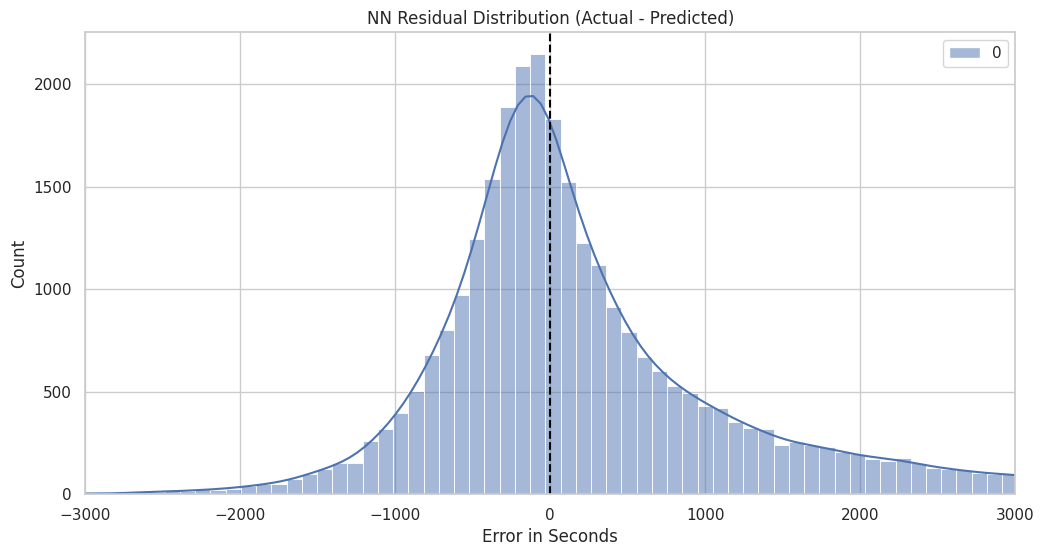

Accuracy within 5 mins: 36.97%
Accuracy within 10 mins: 60.38%
Accuracy within 20 mins: 81.80%


In [67]:
from sklearn.metrics import median_absolute_error, r2_score, mean_squared_log_error

# Calculations using y_actual_seconds and y_final_seconds from previous step
med_ae = median_absolute_error(y_actual_seconds, y_final_seconds)
r2 = r2_score(y_actual_seconds, y_final_seconds)

# Logarithmic error (ensuring no negative values)
msle = mean_squared_log_error(y_actual_seconds, np.clip(y_final_seconds, 0, None))

print(f"Median Absolute Error: {med_ae:.2f} seconds")
print(f"R2 Score (Variance Explained): {r2:.4f}")
print(f"MSLE: {msle:.4f}")

import seaborn as sns
import matplotlib.pyplot as plt

residuals = y_actual_seconds - y_final_seconds

plt.figure(figsize=(12, 6))
sns.histplot(residuals, kde=True, bins=100, color='crimson')
plt.axvline(x=0, color='black', linestyle='--')
plt.title('NN Residual Distribution (Actual - Predicted)')
plt.xlabel('Error in Seconds')
# Focusing on the bulk of the data (-3000 to 3000 seconds)
plt.xlim(-3000, 3000)
plt.show()


# Calculate what % of predictions are within 5, 10, and 20 minutes
errors_abs = np.abs(y_actual_seconds - y_final_seconds)

within_5_min = np.mean(errors_abs <= 300) * 100
within_10_min = np.mean(errors_abs <= 600) * 100
within_20_min = np.mean(errors_abs <= 1200) * 100

print(f"Accuracy within 5 mins: {within_5_min:.2f}%")
print(f"Accuracy within 10 mins: {within_10_min:.2f}%")
print(f"Accuracy within 20 mins: {within_20_min:.2f}%")